## Simple Utility tool agent

This project combines tools + tool calling + LangGraph + Conditional routing + LangSmith tracing.

### Architecture

                         USER
                           │
                           ▼
                    ┌─────────────┐
                    │     LLM     │
                    │ Tool Calling│
                    └──────┬──────┘
                           │
                    Tool required?
                      /          \
                    YES           NO
                     │             │
                     ▼             ▼
                ┌─────────┐    Final Answer
                │ ToolNode│
                └────┬────┘
                     │
                     ▼
                    LLM
                     │
                     ▼
                Final Answer

In [1]:
# 1. Installing the packages
!pip install -U langchain langchain-openai langgraph langsmith

In [31]:
# 2. Importing and reading the environment variables

from dotenv import load_dotenv
# Loads the environment variables from the .env file.

load_dotenv()  # Read the .env file

# 3. Now the LangChain/LangGraph imports:

from typing import TypedDict                                  # Defines the structure of the LangGraph state.
from langchain_core.messages import HumanMessage, SystemMessage  # Represents the message coming from the user
from langchain_core.tools import tool             # @tool decorator converts a python function into a tool that an LLM can call
from langchain_openai import ChatOpenAI           # Provides the OpenAI-compatible chat model used by our agent.
from langgraph.graph import StateGraph, MessagesState, START, END    # Provides the graph-building components and the start/end points of the workflow
from langgraph.prebuilt import ToolNode, tools_condition
# ToolNode executes requested tools, 
# while tools_condition routes based on whether the LLM produced a tool call.
# tools_condition provides the conditional routing based on tool calls.

from datetime import datetime
from zoneinfo import ZoneInfo     # Allows us to work with a specific timezone.
import re                         # Imports Python's regular expression module for detecting sentence-ending punctuation. 
import json                       # Importing for reading data from JSON files.

In [4]:
# 4. Create the LLM
llm = ChatOpenAI(
    model = "gpt-4.1-mini",
    temperature=0
)
# Creates the chat model that will understand the uset's question and decide 
# whether it should answer directly or call one of our tools

Here, temperature = 0 is useful because we want predictable tool selection

In [5]:
# 5. Tool 1 — Calculator

@tool
def calculator(operation: str, a: float, b: float) -> str:
    """
    Perform basic arithmetic operations: add, subtract, multiply, divide, or percentage
    """
    # Converts this Python function into a LangChain tool that the LLM can call.

    if operation == "add":
        # Perform addition when the LLM requests add operation
        
        return str(a + b)   # Returns the addition result as text

    elif operation == "subtract":
        return str(a - b)

    elif operation == "multiply":
        return str(a * b)

    elif operation == "divide":

        if b == 0:
            return "Error: Cannot divide by zero"
        return str(a / b)
        # Returns the division result

    elif operation == "percentage":
        return str((a/100) * b)
        # Example: 18% of 74500 = (18 / 100) * 74500.

    return "Unsupported operation."
    # Return an error if the LLM provides an operation we don't support

In [6]:
# 6. Tool 2 - Current date/time

@tool
def current_datetime() -> str:
    """
    Return the current date and time in United Kingdom.
    """
    # Define the tool that provides the current UK date and time.

    now = datetime.now(ZoneInfo("Europe/London"))
    # Gets the current date and time using the UK timezone.

    return now.strftime("%d %B %Y, %I:%M:%S %p") 
    # Converts the date and time into a human-readable format.

In [7]:
# 7. Tool 3 - Unit Conversion

@tool
def convert_units(value: float, from_unit: str, to_unit: str) -> str:
    """
    Convert common units such as kilometers/miles, meters/feet,
    kilograms/pounds, and Celsius/Fahrenheit.
    """ 
    # Defines a unit-conversion tool that the LLM can call.

    if from_unit == "kilometers" and to_unit == "miles":
        # Checks whether kilometers should be converted to miles.

        result = value * 0.621371
        # Converts kilometers to miles.

    elif from_unit == "miles" and to_unit == "kilometers":
        # Checks for the reverse conversion.

        result = value * 1.60934
        # Converts miles to kilometers.

    elif from_unit == "meters" and to_unit == "feet":
        # Checks for meters-to-feet conversion.

        result = value * 3.28084
        # Converts meters to feet.

    elif from_unit == "feet" and to_unit == "meters":
        # Checks for feet-to-meters conversion.

        result = value * 0.3048
        # Converts feet to meters.

    elif from_unit == "kilograms" and to_unit == "pounds":
        # Checks for kilograms-to-pounds conversion.

        result = value * 2.20462
        # Converts kilograms to pounds.

    elif from_unit == "pounds" and to_unit == "kilograms":
        # Checks for pounds-to-kilograms conversion.

        result = value * 0.453592
        # Converts pounds to kilograms.

    elif from_unit == "celsius" and to_unit == "fahrenheit":
        # Checks for Celsius-to-Fahrenheit conversion.

        result = (value * 9 / 5) + 32
        # Converts Celsius to Fahrenheit.
    
    elif from_unit == "fahrenheit" and to_unit == "celsius":
        # Checks for Fahrenheit-to-Celsius conversion.

        result = (value - 32) * 5 / 9
        # Converts Fahrenheit to Celsius.

    else:
        # Handle unsupported conversions.

        return f"Conversion from {from_unit} to {to_unit} is not supported."
        # Tells the model that this conversion isn't available

    return f"{value} {from_unit} = {result:.4f} {to_unit}" # e.g. 15 kilometers = 9.3206 miles


In [8]:
# 8. Tool 4 - Word/Character counter

@tool
def text_counter(text: str) -> str:
    """
    Count the number of words and characters in a piece of text.
    """
    # Defines a tool that analyze text length

    words = len(text.split())    # Splits the text into words and counts them.
    characters = len(text)       # # Counts the total number of characters, including spaces
    characters_without_spaces = len(text.replace(" ", ""))    # counts characters after removing spaces.
    sentences = len(re.findall(r"[^.!?]*[.!?]", text)) or (1 if text.strip() else 0)
    # Counts sentences ending with '.', '!', or '?'.
    # If text has no ending punctuation but is not empty, counts it as one sentence.

    return (
        f"Words: {words}, "
        f"Sentences: {sentences}"
        f"Characters: {characters}, "
        f"Characters without spaces: {characters_without_spaces}"
    )
    # Returns all three measurements to the LLM.

In [46]:
# 9. Tool 5 - Create the lookup tool
def load_countries():
    with open("data/countries.json", "r", encoding="utf-8") as file:
        return json.load(file)


@tool
def lookup_country_information(country: str) -> str:
    """
    Look up information about a country from the predefined dataset.
    """
    # Defines a LangChain tool that searches for a country
    # in the predefined JSON dataset.

    countries = load_countries()
    # Loads the list of countries from countries.json.

    for item in countries:
        # Loops through every country in the dataset.

        if item["name"].lower() == country.lower():
            # Compares the requested country name with the dataset name.

            return (
                f"Country: {item['name']}\n"
                f"Capital: {item['capital']}\n"
                f"Currency: {item['currency']}\n"
                f"Population: {item['population_millions']} million\n"
                f"Continent: {item['continent']}"
            )
            # Returns the information for the matching country.

    return f"No information found for {country.title()}."
    # Returns this message if the country does not exist in the dataset.

In [47]:
# 11. Putting all the tools together
tools = [
    calculator,
    current_datetime,
    convert_units,
    text_counter,
    lookup_country_information
]
# Create the list of tools that the LLM is allowed to use.

# 12. Bind the tools to the LLM

llm_with_tools = llm.bind_tools(tools)
# Give the LLM access to all the five tools so it can decide when a tool is needed.

The model itself doesn't execute the python function. It requests the tool. ToolNode executes it. In other words, the model requests tools and the application/agent executes them.

In [27]:
# 13. Define the System Prompt

SYSTEM_PROMPT = """
You are a Smart Utility Tool Agent.

You have access to five tools:

1. calculator
2. current_datetime
3. convert_units
4. text_counter
5. lookup_country_information

Rules:

- If the question requires mathematical calculation, you MUST use the calculator tool.

- If the question asks for the current date or time in the United Kingdom,
  you MUST use the current_datetime tool.

- If the question requires unit conversion,
  you MUST use the convert_units tool.

- If the question asks to count words, sentences, or characters,
  you MUST use the text_counter tool.

- If the question asks for information about a country from the predefined
  country dataset, you MUST use the lookup_country_information tool.

- For percentage questions:
  Convert the percentage into a decimal before using the calculator.

  Example:
  18% GST on 74500:
  expression = 74500 * 0.18

  Add 12% to 50000:
  expression = 50000 * 1.12

- If the question does not require a tool,
  answer directly.

- After receiving a tool result,
  provide a clear and concise final answer.
"""
# Defines instructions that tell the LLM when and how to use the tools.

In [28]:
# 14. Create the Agent Node

def agent_node(state: MessagesState):
    # Defines the main AI agent node.

    system = SystemMessage(
        content=SYSTEM_PROMPT
    )
    # Creates a system message containing the agent's instructions.

    response = llm_with_tools.invoke(
        [system] + state["messages"]
    )
    # Sends the system prompt and conversation messages to the LLM.
    # The LLM decides whether to answer directly or request a tool.

    return {
        "messages": [response]
    }
    # Returns the LLM's response and adds it to the graph state.

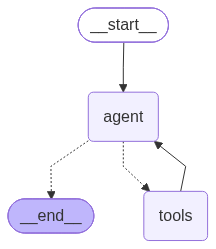

In [29]:
# 14. Create the ToolNode
tool_node = ToolNode(tools)   # Creates a LangGraph node that executes whichever tool the LLM requested.

# 15. Build the LangGraph
builder = StateGraph(MessagesState)   # Creates the LangGraph workflow using MessagesState to store the conversation.

builder.add_node("agent", agent_node)     # Adds the LLM node that decides whether to answer directly or call a tool.
builder.add_node("tools", tool_node)  # Adds the ToolNode that executes the requested tools.

builder.add_edge(START, "agent")        # Starts the workflow by sending the user's request to the LLM.
builder.add_conditional_edges(        # Adding conditional routing
    "agent",
    tools_condition
)

builder.add_edge("tools", "agent")      # After a tool executes, send its result back to the LLM so it can produce the final answer.
smart_utility_agent = builder.compile()     # Compiles the graph into a runnable Smart Utility Agent.
smart_utility_agent

## Test Query

In [32]:
# 1. Test Query 1 — VAT
result = smart_utility_agent.invoke({
    "messages": [
        HumanMessage(
            content="Calculate 18% VAT on £74,500"
        )
    ]
})
# Sends the VAT question to the agent.

In [37]:
print(result["messages"][-1].content)

18% VAT on £74,500 is £13,410.


User -> LLM -> calculator tool -> LLM -> Final answer

In [38]:
# 2. Test Query 2 — Unit conversion
result = smart_utility_agent.invoke({
    "messages": [
        HumanMessage(
            content="Convert 15 kilometers into miles."
        )
    ]
})
# Sends a unit-conversion question to the agent.

In [39]:
print(result["messages"][-1].content)

15 kilometers is approximately 9.32 miles.


In [40]:
# 3. Test Query 3 — Word count

result = smart_utility_agent.invoke({
    "messages": [
        HumanMessage(
            content="How many words are present in this paragraph? "
                    "LangGraph allows us to build stateful agent workflows."
        )
    ]
})
# Sends a text-analysis question to the agent.

In [41]:
print(result["messages"][-1].content)

The paragraph contains 8 words.


In [42]:
# 4. Test Query 4 — Date/time
result = smart_utility_agent.invoke({
    "messages": [
        HumanMessage(
            content="Tell me today's date and current time."
        )
    ]
})
# Sends a current-date/time question to the agent.

In [43]:
print(result["messages"][-1].content)

Today's date is 23 August 2026, and the current time is 08:11 AM in the United Kingdom.


In [58]:
# 5. Test Query 5 — Dataset lookup
result = smart_utility_agent.invoke({
    "messages": [
        HumanMessage(
            content="What is the capital and currency of United Kingdom?"
        )
    ]
})
# Sends a structured-information question to the agent.

In [53]:
print(result["messages"][-1].content)

The capital of the United Kingdom is London, and the currency used is the British Pound Sterling (GBP).


**A query that needs NO tool**

In [54]:
result = smart_utility_agent.invoke({
    "messages": [
        HumanMessage(
            content="What is a vector database?"
        )
    ]
})
# Sends a conceptual question that the LLM can answer without using any utility tool.

User -> LLM -> No tool required -> END

In [55]:
print(result["messages"][-1].content)

A vector database is a specialized type of database designed to store, index, and search high-dimensional vectors efficiently. These vectors often represent complex data such as images, text, audio, or other forms of unstructured data that have been transformed into numerical vector representations through techniques like machine learning or deep learning.

Vector databases are particularly useful for similarity search tasks, where the goal is to find items that are most similar to a given query vector. This is common in applications like recommendation systems, image and video retrieval, natural language processing, and more.

Key features of vector databases include:
- Efficient storage of high-dimensional vectors.
- Fast similarity search using metrics like cosine similarity, Euclidean distance, or inner product.
- Support for approximate nearest neighbor (ANN) search algorithms to handle large-scale data with reduced computational cost.

In summary, a vector database enables effect

In [59]:
for message in result["messages"]:
    # Goes through every message generated during the agent execution.

    message.pretty_print()
    # Prints each HumanMessage, AIMessage, and ToolMessage in a readable format.

================================ Human Message =================================

What is the capital and currency of United Kingdom?
================================== Ai Message ==================================
Tool Calls:
  lookup_country_information (call_Wy9LTJIOhEXtTueJW7CZrEIk)
 Call ID: call_Wy9LTJIOhEXtTueJW7CZrEIk
  Args:
    country: United Kingdom
================================= Tool Message =================================
Name: lookup_country_information

Error: lookup_country_information is not a valid tool, try one of [calculator, current_datetime, convert_units, text_counter, lookup_information].
================================== Ai Message ==================================
Tool Calls:
  lookup_country_information (call_2Q8ixtS9YoG5E3Mk27YTBhzw)
 Call ID: call_2Q8ixtS9YoG5E3Mk27YTBhzw
  Args:
    country: United Kingdom
================================= Tool Message =================================
Name: lookup_country_information

Error: lookup_country_informa

## Smart Utility Agent Architecture

```text
Smart Utility Agent
│
├── User Request
│
├── LLM
│   └── Tool Call: convert_units
│
├── ToolNode
│   └── convert_units
│
└── LLM
    └── Final Answer
```